In [5]:
from background.modules.exchange_upbit import ExChangeUpbit
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import os

import datetime

In [91]:
interval = "minute5"
count = 200
days = 93

In [92]:
def cut_by_days(end_dt, df, days):
    start = end_dt - datetime.timedelta(days=days)
    return df[df["datetime"] >= start].copy()

In [101]:


end_dt = datetime.datetime.now()
start_dt = end_dt - datetime.timedelta(days=days)

dfs = []
to = end_dt
max_call = int((days * 24 * 12) / count) + 2

for _ in range(max_call):
    df = upbit.get_ohlcv(
        interval=interval,
        date=to.strftime("%Y-%m-%d %H:%M:%S"),
        count=count
    )

    if df is None or df.empty:
        break

    dfs.append(df)

    oldest_dt = df["datetime"].iloc[0]

    # 30일 이전이면 종료
    if oldest_dt <= start_dt:
        break

    # 다음 호출 기준점
    to = oldest_dt - datetime.timedelta(minutes=5)

df_combined = (
    pd.concat(dfs)
    .drop_duplicates(subset="datetime")
    .sort_values("datetime")
    .reset_index(drop=True)
)

# 1. timestamp 컬럼 datetime 변환 (unit='s' 또는 'ms' 꼭 지정)
df_combined["timestamp"] = df_combined["datetime"].astype("int64") // 10**9
df_combined['timestamp'] = pd.to_datetime(df_combined['timestamp'], unit='s')

# 2. 시간대 추출 (예: 시(hour))
df_combined['hour'] = df_combined['timestamp'].dt.hour
df_combined['minute'] = df_combined['timestamp'].dt.minute

# 요일 (문자)
df_combined["weekday"] = df_combined["datetime"].dt.day_name()

# 요일 (숫자: 월=0 ~ 일=6)
df_combined["weekday_num"] = df_combined["datetime"].dt.weekday

# 다음 종가
df_combined["next_close"] = df_combined["close"].shift(-1)

# 변화량 (미래 - 현재)
df_combined["future_change"] = df_combined["next_close"] - df_combined["close"]

# 변화율 (%)
df_combined["future_change_pct"] = (df_combined["future_change"] / df_combined["close"]) * 100

# 방향
df_combined["future_direction"] = df_combined["future_change_pct"].apply(
    lambda x: "UP" if x > 0 else ("DOWN" if x < -0 else "FLAT")
)

df_combined["future_direction_num"] = df_combined["future_change_pct"].apply(
    lambda x: 1 if x > 0 else (-1 if x < -0 else 0)
)

# 캔들 방향
df_combined["candle_direction"] = df_combined.apply(
    lambda x: 1 if x["close"] > x["open"]
    else (-1 if x["close"] < x["open"] else 0),
    axis=1
)

# 방향성 거래량
df_combined["signed_volume"] = df_combined["volume"] * df_combined["candle_direction"]

# 양/음 거래량 분리
df_combined["pos_volume"] = df_combined["signed_volume"].apply(lambda x: x if x > 0 else 0)
df_combined["neg_volume"] = df_combined["signed_volume"].apply(lambda x: abs(x) if x < 0 else 0)

df_combined["volume_delta"] = df_combined["pos_volume"] - df_combined["neg_volume"]

df_combined["volume_imbalance"] = (
    df_combined["pos_volume"] - df_combined["neg_volume"]
) / (
    df_combined["pos_volume"] + df_combined["neg_volume"] + 1e-9
)

In [103]:
df_2w  = cut_by_days(end_dt, df_combined, 14)
df_3w  = cut_by_days(end_dt, df_combined, 21)
df_1m  = cut_by_days(end_dt, df_combined, 30)
df_2m  = cut_by_days(end_dt, df_combined, 60)
df_3m  = df_combined

df_3m.head(10)
#df_combined.head(10)

,open,high,low,close,volume,value,datetime,timestamp,hour,minute,...,future_change,future_change_pct,future_direction,future_direction_num,candle_direction,signed_volume,pos_volume,neg_volume,volume_delta,volume_imbalance
0,163716000.0,164074000.0,163700000.0,163938000.0,5.826538,9.549294e+08,2025-10-23 21:05:00,2025-10-23 21:05:00,21,5,...,142000.0,0.086618,UP,1,1,5.826538,5.826538,0.000000,5.826538,1.0
1,163940000.0,164100000.0,163938000.0,164080000.0,1.695709,2.782011e+08,2025-10-23 21:10:00,2025-10-23 21:10:00,21,10,...,120000.0,0.073135,UP,1,1,1.695709,1.695709,0.000000,1.695709,1.0
2,164080000.0,164226000.0,163967000.0,164200000.0,2.928356,4.804805e+08,2025-10-23 21:15:00,2025-10-23 21:15:00,21,15,...,-131000.0,-0.079781,DOWN,-1,1,2.928356,2.928356,0.000000,2.928356,1.0
3,164147000.0,164272000.0,164006000.0,164069000.0,4.825541,7.919868e+08,2025-10-23 21:20:00,2025-10-23 21:20:00,21,20,...,194000.0,0.118243,UP,1,-1,-4.825541,0.000000,4.825541,-4.825541,-1.0
4,164240000.0,164279000.0,164095000.0,164263000.0,2.383982,3.915135e+08,2025-10-23 21:25:00,2025-10-23 21:25:00,21,25,...,-217000.0,-0.132105,DOWN,-1,1,2.383982,2.383982,0.000000,2.383982,1.0
5,164222000.0,164263000.0,163837000.0,164046000.0,5.592091,9.170467e+08,2025-10-23 21:30:00,2025-10-23 21:30:00,21,30,...,-71000.0,-0.043281,DOWN,-1,-1,-5.592091,0.000000,5.592091,-5.592091,-1.0
6,164046000.0,164047000.0,163800000.0,163975000.0,4.956974,8.123960e+08,2025-10-23 21:35:00,2025-10-23 21:35:00,21,35,...,218000.0,0.132947,UP,1,-1,-4.956974,0.000000,4.956974,-4.956974,-1.0
7,163891000.0,164201000.0,163891000.0,164193000.0,2.009053,3.295902e+08,2025-10-23 21:40:00,2025-10-23 21:40:00,21,40,...,17000.0,0.010354,UP,1,1,2.009053,2.009053,0.000000,2.009053,1.0
8,164193000.0,164252000.0,164061000.0,164210000.0,2.516032,4.130822e+08,2025-10-23 21:45:00,2025-10-23 21:45:00,21,45,...,-145000.0,-0.088302,DOWN,-1,1,2.516032,2.516032,0.000000,2.516032,1.0
9,164210000.0,164211000.0,164060000.0,164065000.0,1.984213,3.256741e+08,2025-10-23 21:50:00,2025-10-23 21:50:00,21,50,...,185000.0,0.112760,UP,1,-1,-1.984213,0.000000,1.984213,-1.984213,-1.0


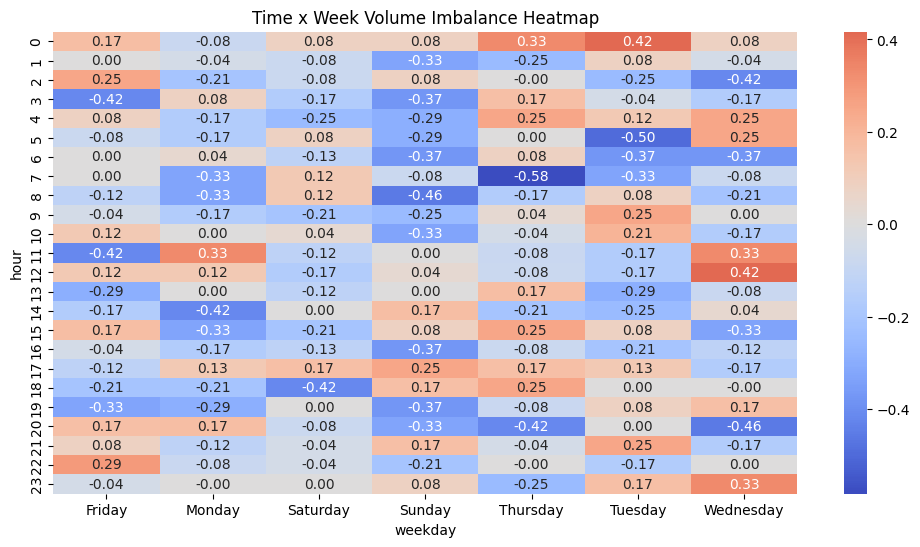

In [106]:
# # 3) 시간대별 평균 등락률 (numeric 타입일 경우)
# hourly_mean_change = df_combined.groupby('hour')['future_direction_num'].mean()

# plt.figure(figsize=(10, 5))
# sns.lineplot(x=hourly_mean_change.index, y=hourly_mean_change.values)
# plt.title('Average future_direction_num by hour')
# plt.grid(True)
# plt.show()

# # 4) 요일별 등락률 평균
# weekday_mean_change = df_combined.groupby('weekday')['future_direction_num'].mean()

# plt.figure(figsize=(8, 4))
# sns.barplot(x=weekday_mean_change.index, y=weekday_mean_change.values)
# plt.title('Average future_direction_num by Week')
# plt.show()

# # 5) 시간대별 x 요일별 heatmap 시각화 (pivot table)
# pivot = df_combined.pivot_table(values='future_direction_num', index='hour', columns='weekday', aggfunc='mean')

# #plt.figure(figsize=(60, 6))
# plt.figure(figsize=(12, 6))
# sns.heatmap(pivot, annot=True, fmt=".2f", cmap="coolwarm")
# plt.title('time x week avg updown rate Heatmap')
# plt.show()
pivot_vol = df_2w.pivot_table(
    values="volume_imbalance",
    index="hour",
    columns="weekday",
    aggfunc="mean"
)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_vol, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Time x Week Volume Imbalance Heatmap")
plt.show()

In [ ]:
# 설정 된 티커들에 대해
# 3달간, 2달간, 1달간, 3주간, 2주간 히트맵 뽑기
# 최장치 뽑은다음에 날짜를 컷하면 되겠지?? 
# 그러고 민아이오에 올리고 